In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df=pd.read_csv('/content/healthcare_data_for_task - healthcare_data_for_task.csv')

In [3]:
df.head()

,Patient_ID,Age,Gender,Blood_Type,Medical_Condition,Medical_Code,Date_of_Admission,Discharge_Date,Admission_Type,Billing_Amount
0,P0001,47,Male,AB+,Heart Disease,HEA004,2025-05-10,2025-05-16,Emergency,23218.31
1,P0002,62,Female,AB-,Diabetes,DIA001,2025-12-31,2026-01-02,Emergency,47010.56
2,P0003,36,Male,AB-,Heart Disease,HEA004,2025-11-10,2025-11-27,Emergency,39619.01
3,P0004,51,Male,A+,Heart Disease,HEA004,2023-05-02,2023-05-07,Elective,35963.71
4,P0005,30,Male,A+,Diabetes,DIA001,2024-04-11,2024-04-17,Urgent,64615.93


In [4]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition',
       'Medical_Code', 'Date_of_Admission', 'Discharge_Date', 'Admission_Type',
       'Billing_Amount'],
      dtype='object')

In [6]:
df.shape

(1000, 10)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         1000 non-null   object 
 1   Age                1000 non-null   int64  
 2   Gender             1000 non-null   object 
 3   Blood_Type         1000 non-null   object 
 4   Medical_Condition  1000 non-null   object 
 5   Medical_Code       970 non-null    object 
 6   Date_of_Admission  1000 non-null   object 
 7   Discharge_Date     1000 non-null   object 
 8   Admission_Type     1000 non-null   object 
 9   Billing_Amount     1000 non-null   float64
dtypes: float64(1), int64(1), object(8)
memory usage: 78.3+ KB


In [8]:
df.describe()

,Age,Billing_Amount
count,1000.000000,1000.000000
mean,51.888000,77117.515720
std,19.256954,41955.242269
min,18.000000,5568.160000
25%,35.750000,40318.785000
50%,52.000000,77293.900000
75%,69.000000,113089.267500
max,85.000000,149921.800000


In [9]:
df['Date_of_Admission']=pd.to_datetime(df['Date_of_Admission'])

In [10]:
df['Discharge_Date']=pd.to_datetime(df['Discharge_Date'])

In [11]:
df.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
Blood_Type,0
Medical_Condition,0
Medical_Code,30
Date_of_Admission,0
Discharge_Date,0
Admission_Type,0
Billing_Amount,0


In [12]:
df['Admission_Type'].unique()

array(['Emergency', 'Elective', 'Urgent', 'urgent', 'ELECTIVE',
       'elective', 'URGENT', 'emergency', 'EMERGENCY'], dtype=object)

In [16]:
Stay_Days=(df['Discharge_Date']-df['Date_of_Admission']).dt.days

In [17]:
df['Date_of_Admission'].dt.month

,Date_of_Admission
0,5
1,12
2,11
3,5
4,4
...,...
995,3
996,4
997,5
998,2


In [18]:
df['Date_of_Admission'].dt.year

,Date_of_Admission
0,2025
1,2025
2,2025
3,2023
4,2024
...,...
995,2023
996,2025
997,2023
998,2023


In [22]:
df['Date_of_Admission'].dt.day

,Date_of_Admission
0,10
1,31
2,10
3,2
4,11
...,...
995,16
996,17
997,8
998,11


<Axes: xlabel='Admission_Type'>

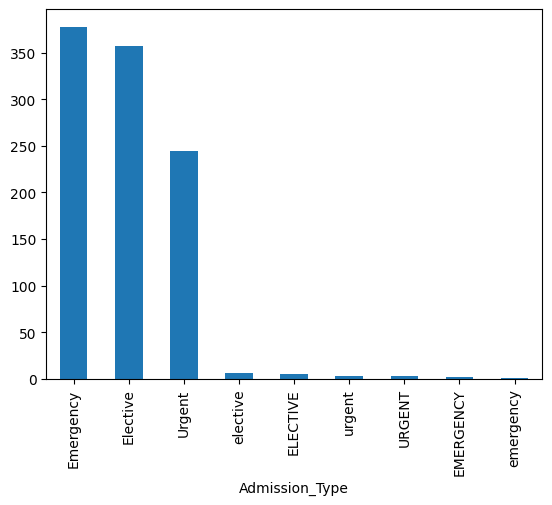

In [30]:
df['Admission_Type'].value_counts().plot(kind='bar')

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Heart Disease'),
  Text(1, 0, 'Diabetes'),
  Text(2, 0, 'Arthritis'),
  Text(3, 0, 'Hypertension'),
  Text(4, 0, 'Asthma')])

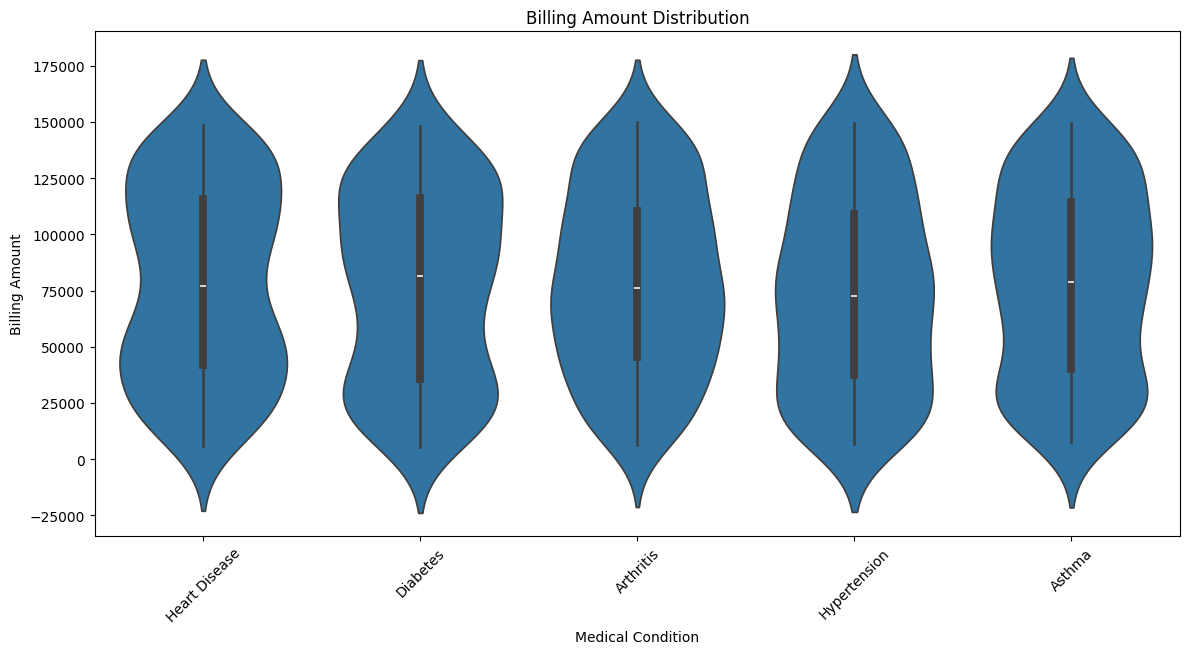

In [33]:
plt.figure(figsize=(12,6))
sns.violinplot(
    data=df,
    x='Medical_Condition',
    y='Billing_Amount'
)
plt.title('Billing Amount Distribution')
plt.xlabel('Medical Condition')
plt.ylabel('Billing Amount')
plt.tight_layout()
plt.xticks(rotation=45)


In [35]:
billing_summary=(
    df.groupby(['Medical_Condition','Admission_Type'])['Billing_Amount']
    .sum()
    .unstack()
)

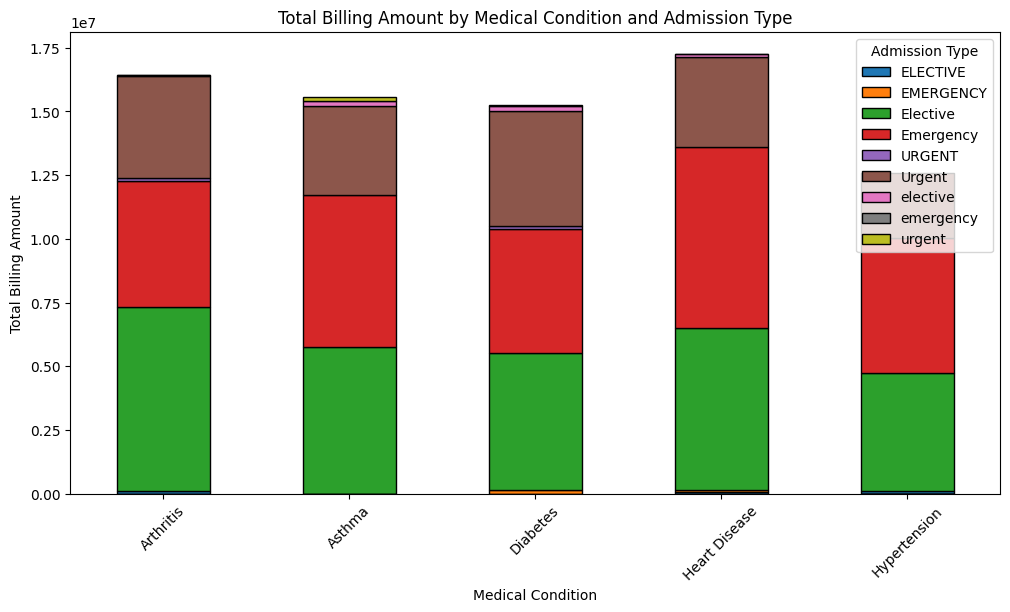

In [36]:
billing_summary.plot(kind='bar',
                     stacked=True,
                     figsize=(12,6),
                     edgecolor='black',
                     )

plt.title('Total Billing Amount by Medical Condition and Admission Type')

plt.xlabel('Medical Condition')
plt.ylabel('Total Billing Amount')

plt.xticks(rotation=45)
plt.legend(title='Admission Type')

plt.show()